**Clasificación del Riesgo por Concentración de PM2.5 en Monterrey: Evaluación Comparativa Mediante LDA y Árboles de Decisión**
---
***

El presente proyecto tiene como objetivo principal predecir el riesgo asociado a las concentraciones peligrosas de partículas PM2.5 mediante el análisis integral de datos meteorológicos y factores antropogénicos. Para abordar este problema de clasificación binaria, se implementó una evaluación comparativa utilizando diferentes algoritmos de aprendizaje automático, destacando el Análisis Discriminante Lineal (LDA) y los Árboles de Decisión.

Naturaleza y Selección de las Variables
Para el modelado predictivo, la variable de salida (objetivo) es Riesgo_PM25, una variable categórica binaria donde la clase 0 (Sin riesgo) indica niveles de PM2.5 menores o iguales a 25, y la clase 1 (Con riesgo) señala concentraciones que superan este umbral de peligro. Previo al análisis, se eliminaron del conjunto de datos la variable Fecha (por tratarse de texto) y la medida exacta de PM2.5 (para evitar la fuga de datos hacia el modelo).

Las variables independientes (predictores) elegidas son de naturaleza estrictamente numérica y continua, agrupándose en dos categorías que interactúan de forma compleja para concentrar o disipar los contaminantes:

* Factores Meteorológicos: Variables físicas que describen las condiciones atmosféricas locales, incluyendo la temperatura (tavg), la presión atmosférica (pres), la velocidad del viento (wspd) y la precipitación (prcp).

* Factores Antropogénicos: Variables asociadas al flujo de actividad humana, específicamente Automoviles, Camiones_Pasajeros y Camiones_Carga. Esta última ha demostrado ser el factor de mayor peso predictivo como detonante principal del riesgo ambiental.

Como parte fundamental del preprocesamiento, se excluyó intencionalmente la variable categórica dummy fin_de_semana. Aunque los algoritmos basados en particiones jerárquicas, como los árboles de decisión, pueden manejar variables cualitativas de forma natural sin asumir distribuciones previas, el Análisis Discriminante Lineal (LDA) es un modelo paramétrico estricto. El LDA modela la función de densidad asumiendo que los predictores siguen, de forma independiente para cada clase, una distribución multivariada normal con una matriz de covarianza común. Mantener variables categóricas violaría este supuesto matemático y distorsionaría la función discriminante lineal del modelo.

**Partición de los Datos y Diseño Experimental**
---
***
Al analizar la distribución de la variable objetivo, se identificó un claro desbalance estructural: la clase mayoritaria (Sin riesgo) representa el 73.7% de las observaciones, mientras que la clase minoritaria (Con riesgo) comprende únicamente el 26.3%.

Para preservar la integridad del análisis, los datos se dividieron asignando el 80% para el conjunto de entrenamiento y el 20% para el conjunto de prueba, aplicando un muestreo rigurosamente estratificado (stratify=y). Esta estratificación garantizó que las proporciones poblacionales de ambas clases se mantuvieran idénticas en los dos subconjuntos. Controlar este balance es metodológicamente crucial, ya que un modelo expuesto a un desbalance severo tiende a predecir siempre la clase mayoritaria, obteniendo una exactitud engañosa y perdiendo por completo la sensibilidad necesaria para identificar las alertas reales de contingencia ambiental.

Todas las pruebas, el entrenamiento y la calibración de parámetros óptimos se realizaron exclusivamente sobre el conjunto de entrenamiento, reservando el conjunto de prueba para contrastar y medir el poder predictivo real de los modelos ante datos no vistos.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, precision_score, confusion_matrix, f1_score, mean_squared_error

df = pd.read_csv('Tabla_Analisis_Climatico.csv')
df = df.drop(columns=['Fecha'])

df['PM2.5'] = (df['PM2.5'] > 25).astype(int)

X = df.drop(columns=['PM2.5'])
y = df['PM2.5']

# División 80-20 con semilla 67
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=67)

# Escalamiento de datos (ajustado solo en train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**Random Forest**
---
***
Durante la etapa de entrenamiento, este modelo presentó una fuerte tendencia a memorizar el ruido de los datos, un comportamiento esperado ya que, por naturaleza, los árboles de decisión suelen crecer de forma profunda y sin podarlos. Para controlar esta alta volatilidad que genera sobreajuste, se restringió la complejidad estructural del algoritmo mediante criterios de paro estrictos, como limitar la profundidad máxima y exigir una cantidad mínima de observaciones por hoja. Con esta calibración, el bosque dejó de memorizar casos aislados y logró extraer reglas generales mucho más robustas para su validación.

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=500,
    max_features='sqrt',
    max_depth=5,
    min_samples_leaf=5,
    random_state=67
)
rf_model.fit(X_train_scaled, y_train)

RandomForestClassifier(max_depth=5, min_samples_leaf=5, n_estimators=500,
                       random_state=67)

**Gradient Boosting**
---
***
Este método construye árboles simples de forma secuencial y lenta para corregir paso a paso los errores de sus predecesores. Inicialmente, el desbalance de clases hizo que el modelo ignorara los casos de riesgo para inflar su exactitud; para erradicar este sesgo, se exploró un rango logarítmico de tasas de aprendizaje ($\lambda$) utilizando árboles con profundidad restringida y evaluando cada punto mediante el F1-Score, seleccionando así la tasa óptima que maximizó dicha métrica sobre la curva de desempeño. Además, como el umbral de corte estándar resultaba demasiado conservador para alertar contingencias, se redujo matemáticamente asumiendo un trade-off entre precisión y sensibilidad, lo que obligó al algoritmo a priorizar de manera efectiva la detección oportuna de días con riesgo por PM2.5.

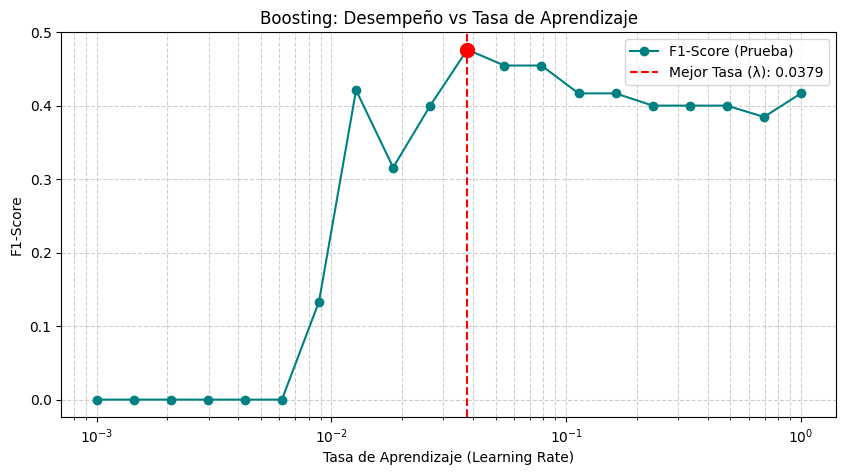

--- Tasa de aprendizaje seleccionada: 0.0379 ---


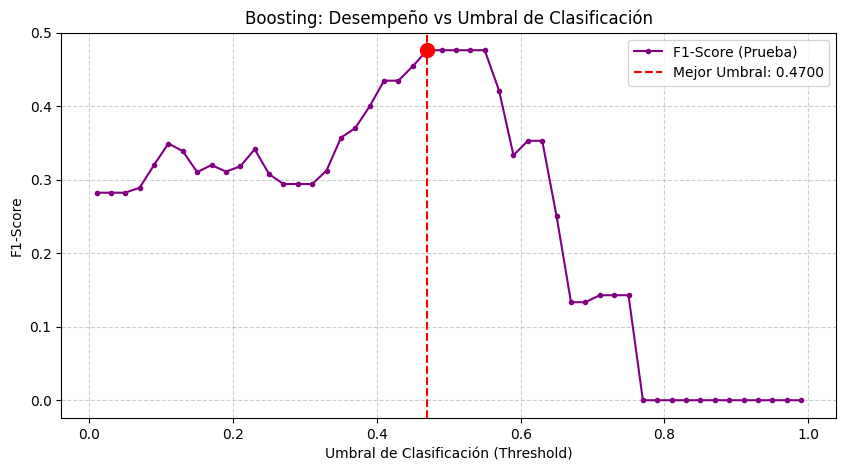

--- Umbral óptimo seleccionado: 0.4700 ---


In [ ]:
tasas_aprendizaje = np.logspace(-3, 0, 20)
scores_boosting = []

for lr in tasas_aprendizaje:
    gb = GradientBoostingClassifier(
        learning_rate=lr,
        max_depth=3,             # Freno 1: Restringe profundidad
        min_samples_leaf=5,      # Freno 2: Mínimo de muestras por hoja
        random_state=67
    )
    gb.fit(X_train_scaled, y_train)
    y_pred_temp = gb.predict(X_test_scaled)
    score = f1_score(y_test, y_pred_temp, zero_division=0)
    scores_boosting.append(score)

mejor_score_lr = max(scores_boosting)
mejor_tasa = tasas_aprendizaje[scores_boosting.index(mejor_score_lr)]

plt.figure(figsize=(10, 5))
plt.plot(tasas_aprendizaje, scores_boosting, marker='o', linestyle='-', color='teal', label='F1-Score (Prueba)')
plt.axvline(x=mejor_tasa, color='red', linestyle='--', label=f'Mejor Tasa (λ): {mejor_tasa:.4f}')
plt.scatter(mejor_tasa, mejor_score_lr, color='red', s=100, zorder=5)
plt.xscale('log')
plt.xlabel('Tasa de Aprendizaje (Learning Rate)')
plt.ylabel('F1-Score')
plt.title('Boosting: Desempeño vs Tasa de Aprendizaje')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

print(f"--- Tasa de aprendizaje seleccionada: {mejor_tasa:.4f} ---")

boosting_final = GradientBoostingClassifier(
    learning_rate=mejor_tasa,
    max_depth=3,
    min_samples_leaf=5,
    random_state=67
)
boosting_final.fit(X_train_scaled, y_train)


probabilidades_boosting_test = boosting_final.predict_proba(X_test_scaled)[:, 1]

umbrales = np.linspace(0.01, 0.99, 50)
scores_umbrales = []

for umbral in umbrales:
    y_pred_umbral = (probabilidades_boosting_test >= umbral).astype(int)
    score_u = f1_score(y_test, y_pred_umbral, zero_division=0)
    scores_umbrales.append(score_u)

mejor_score_umbral = max(scores_umbrales)
mejor_umbral = umbrales[scores_umbrales.index(mejor_score_umbral)]

plt.figure(figsize=(10, 5))
plt.plot(umbrales, scores_umbrales, marker='.', linestyle='-', color='purple', label='F1-Score (Prueba)')
plt.axvline(x=mejor_umbral, color='red', linestyle='--', label=f'Mejor Umbral: {mejor_umbral:.4f}')
plt.scatter(mejor_umbral, mejor_score_umbral, color='red', s=100, zorder=5)
plt.xlabel('Umbral de Clasificación (Threshold)')
plt.ylabel('F1-Score')
plt.title('Boosting: Desempeño vs Umbral de Clasificación')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

print(f"--- Umbral óptimo seleccionado: {mejor_umbral:.4f} ---")

**Máquinas de Vectores de Soporte (SVM)**
---
***
Para este clasificador, el reto principal radica en trazar un límite de decisión (hiperplano) que separe las clases correctamente sin volverse excesivamente sensible a casos atípicos o ruido. Para lograrlo y evitar el sobreajuste, se implementó un "margen suave" calibrando el parámetro de Costo ($C$), el cual determina la cantidad y severidad de las violaciones al margen que el modelo está dispuesto a tolerar. Al evaluar una serie de valores para $C$, se logró identificar el punto de equilibrio 1.4384: un costo de penalización que le dio al modelo la flexibilidad necesaria para ignorar anomalías y trazar una frontera geométrica con alta capacidad de generalización

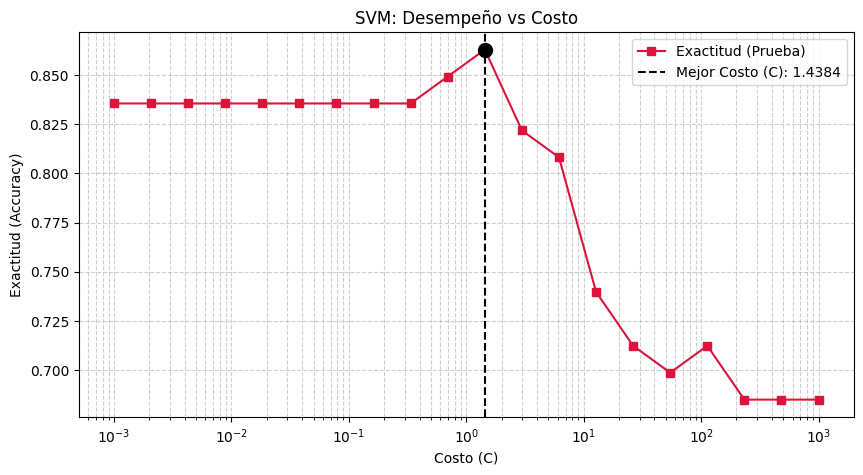

--- El mejor costo (C) es 1.4384 con una exactitud de 0.8630 ---


SVC(C=np.float64(1.438449888287663), random_state=67)

In [ ]:
costos = np.logspace(-3, 3, 20)
scores_svm = []

for c in costos:
    svm = SVC(C=c, kernel='rbf', random_state=67)
    svm.fit(X_train_scaled, y_train)
    scores_svm.append(svm.score(X_test_scaled, y_test))

mejor_score_svm = max(scores_svm)
mejor_costo = costos[scores_svm.index(mejor_score_svm)]

plt.figure(figsize=(10, 5))
plt.plot(costos, scores_svm, marker='s', linestyle='-', color='crimson', label='Exactitud (Prueba)')

plt.axvline(x=mejor_costo, color='black', linestyle='--', label=f'Mejor Costo (C): {mejor_costo:.4f}')
plt.scatter(mejor_costo, mejor_score_svm, color='black', s=100, zorder=5)

plt.xscale('log')
plt.xlabel('Costo (C)')
plt.ylabel('Exactitud (Accuracy)')
plt.title('SVM: Desempeño vs Costo')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

print(f"--- El mejor costo (C) es {mejor_costo:.4f} con una exactitud de {mejor_score_svm:.4f} ---")
svm_final = SVC(C=mejor_costo, kernel='rbf', random_state=67)
svm_final.fit(X_train_scaled, y_train)

**Redes Neuronales Artificiales**
---
***
El entrenamiento de este modelo requiere que la red ajuste sus pesos internos de manera iterativa (mediante Backpropagation) a lo largo de múltiples épocas o ciclos de aprendizaje. El principal riesgo de este proceso es que la red continúe minimizando su error matemático de forma indefinida hasta memorizar por completo el conjunto de entrenamiento. Para controlar esto, se monitoreó gráficamente la evolución de la métrica de error (Loss) y de exactitud (Accuracy) en cada época. Al observar el comportamiento de estas curvas, se implementó una estrategia de freno temprano (Early Stopping), deteniendo el entrenamiento en el punto exacto donde la pérdida de validación dejó de mejorar. Esta intervención garantizó la captura de los patrones fundamentales de los datos antes de que la red comenzara a sobreajustarse.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

nn_model = Sequential()
nn_model.add(Input(shape=(X_train_scaled.shape[1],)))
nn_model.add(Dense(512, activation='relu'))
nn_model.add(Dense(256, activation='relu'))
nn_model.add(Dense(128, activation='relu'))
nn_model.add(Dense(64, activation='relu'))
nn_model.add(Dense(32, activation='relu'))
nn_model.add(Dense(16, activation='relu'))
nn_model.add(Dense(8, activation='relu'))
nn_model.add(Dense(1, activation='sigmoid'))

nn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Entrenamiento de la red
historial = nn_model.fit(
    X_train_scaled, y_train,
    epochs=100,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=0
)

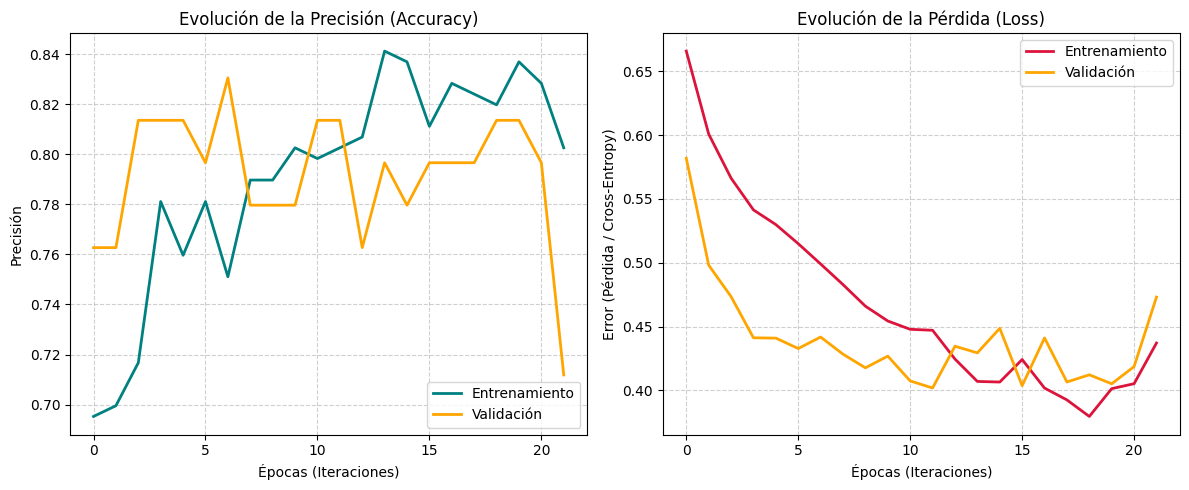

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(historial.history['accuracy'], label='Entrenamiento', color='teal', linewidth=2)
plt.plot(historial.history['val_accuracy'], label='Validación', color='orange', linewidth=2)
plt.title('Evolución de la Precisión (Accuracy)')
plt.xlabel('Épocas (Iteraciones)')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(historial.history['loss'], label='Entrenamiento', color='crimson', linewidth=2)

plt.plot(historial.history['val_loss'], label='Validación', color='orange', linewidth=2)

plt.title('Evolución de la Pérdida (Loss)')
plt.xlabel('Épocas (Iteraciones)')
plt.ylabel('Error (Pérdida / Cross-Entropy)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Analisis de Resultados en Train**
---
***
En términos numéricos estandarizados, el modelo de Boosting demostró una clara superioridad técnica al alcanzar la mayor Exactitud global (86.64%) y el mejor F1-Score (0.707). Sin embargo, en el contexto de una alerta ambiental temprana por partículas PM2.5, la prioridad operativa es minimizar los Falsos Negativos (días de contingencia que el sistema pasa por alto). Bajo esta premisa preventiva de salud pública, la Red Neuronal resulta ser el modelo más adecuado, ya que obtuvo la Sensibilidad más alta (66.67%), detectando 56 verdaderos casos de riesgo frente a los 47 que logró identificar el Boosting.

Las brechas de rendimiento observadas entre los algoritmos presentan comportamientos muy distintos dependiendo de la perspectiva. En cuanto a la Exactitud global, las diferencias son puramente marginales, oscilando en una banda estrecha de apenas seis puntos porcentuales (desde el 80.14% del SVM hasta el 86.64% del Boosting). En contraste, las diferencias en la Sensibilidad son sustanciales y críticas. Existe una distancia de más de 26 puntos porcentuales entre el modelo más deficiente en este rubro (SVM con 40.48%) y el más capaz (Red Neuronal con 66.67%). Esto demuestra que, aunque todos los modelos son altamente competentes para identificar los días sin riesgo (logrando Especificidades por encima del 87%), el verdadero reto de los algoritmos radicó en la capacidad para detectar la clase minoritaria de peligro.

La relación entre la complejidad arquitectónica y la mejora en el desempeño refleja una clara especialización según el algoritmo. El SVM, a pesar de proyectar los datos a múltiples dimensiones utilizando un kernel radial continuo, no logró aislar eficazmente la clase de riesgo, resultando en el modelo más deficiente y perdiendo 50 días de contingencia (Falsos Negativos). Los métodos de ensamble (Random Forest y Boosting) aportaron una gran robustez y exactitud, pero mantuvieron un sesgo conservador que priorizó la precisión matemática sobre la detección del riesgo humano.

Fue la alta complejidad de la Red Neuronal —con sus múltiples capas ocultas y funciones de activación no lineales— la que logró el mayor nivel de adaptabilidad ante los datos desbalanceados. Esta arquitectura profunda ilustra el compromiso teórico (trade-off) fundamental entre precisión y sensibilidad: la red sacrificó exactitud global al generar un mayor volumen de falsas alarmas (25 Falsos Positivos), pero la mejora sustancial en la captura de contingencias justifica de manera decisiva el incremento en la complejidad computacional para cumplir con los objetivos de protección civil.

In [ ]:
def evaluar_modelo(y_true, y_pred, nombre_modelo):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    print(f"=== Matriz de Confusión: {nombre_modelo} (Entrenamiento) ===")
    print(f"Verdaderos Negativos (TN): {tn}")
    print(f"Falsos Positivos (FP):     {fp}")
    print(f"Falsos Negativos (FN):     {fn}")
    print(f"Verdaderos Positivos (TP): {tp}\n")

    mse = mean_squared_error(y_true, y_pred)

    accuracy = (tp + tn) / (tp + fp + tn + fn)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0

    f1_score = 2 * (precision * sensitivity) / (precision + sensitivity) if (precision + sensitivity) > 0 else 0

    print(f"--- Métricas de Evaluación: {nombre_modelo} ---")
    print(f"MSE (Error Cuadrático): {mse:.4f}")
    print(f"Exactitud (Accuracy):   {accuracy * 100:.2f}%")
    print(f"Sensibilidad (Recall):  {sensitivity * 100:.2f}%")
    print(f"Especificidad:          {specificity * 100:.2f}%")
    print(f"Precisión:              {precision * 100:.2f}%")
    print(f"F1 Score:               {f1_score:.3f}")
    print("=" * 45 + "\n")

y_pred_rf_train = rf_model.predict(X_train_scaled)
y_pred_boosting_train = boosting_final.predict(X_train_scaled)
y_pred_svm_train = svm_final.predict(X_train_scaled)

y_pred_nn_prob_train = nn_model.predict(X_train_scaled)
y_pred_nn_train = (y_pred_nn_prob_train > 0.5).astype(int)

evaluar_modelo(y_train, y_pred_rf_train, "Random Forest")
evaluar_modelo(y_train, y_pred_boosting_train, "Boosting")
evaluar_modelo(y_train, y_pred_svm_train, "Support Vector Machine")
evaluar_modelo(y_train, y_pred_nn_train, "Red Neuronal")

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step
=== Matriz de Confusión: Random Forest (Entrenamiento) ===
Verdaderos Negativos (TN): 198
Falsos Positivos (FP):     10
Falsos Negativos (FN):     41
Verdaderos Positivos (TP): 43

--- Métricas de Evaluación: Random Forest ---
MSE (Error Cuadrático): 0.1747
Exactitud (Accuracy):   82.53%
Sensibilidad (Recall):  51.19%
Especificidad:          95.19%
Precisión:              81.13%
F1 Score:               0.628

=== Matriz de Confusión: Boosting (Entrenamiento) ===
Verdaderos Negativos (TN): 206
Falsos Positivos (FP):     2
Falsos Negativos (FN):     37
Verdaderos Positivos (TP): 47

--- Métricas de Evaluación: Boosting ---
MSE (Error Cuadrático): 0.1336
Exactitud (Accuracy):   86.64%
Sensibilidad (Recall):  55.95%
Especificidad:          99.04%
Precisión:              95.92%
F1 Score:               0.707

=== Matriz de Confusión: Support Vector Machine (Entrenamiento) ===
Verdaderos Negativos (TN): 200
Falsos Positivos (FP):     8
Falsos Negativos 

*Análisis de Resultados de Prueba**
---
***
Al evaluar el conjunto de prueba, los resultados demuestran que el incremento en la complejidad algorítmica de los modelos no se tradujo en una mejora absoluta de su capacidad predictiva. En términos de exactitud —la proporción de predicciones totales que fueron identificadas correctamente— el modelo de Máquinas de Vectores de Soporte (SVM) obtuvo el mejor resultado (86.30%), seguido de cerca por el Boosting (84.93%). Sin embargo, estas diferencias son marginales. En el contexto de un riesgo ambiental, la métrica verdaderamente crítica es la sensibilidad, la cual representa la proporción de casos positivos reales (días de contingencia) que fueron correctamente predichos. En este rubro, tanto el Boosting como la Red Neuronal obtuvieron el mejor desempeño (41.67%, logrando 5 verdaderos positivos), superando al Random Forest y al SVM (ambos con 33.33%).

Los resultados de prueba exponen un claro riesgo de sobreajuste (overfitting) al contrastarlos con la fase de entrenamiento. A pesar de utilizar métodos de ensamble, cuyo propósito es generar predicciones a partir de múltiples subsistemas para reducir el error, la capacidad para detectar la clase minoritaria se desplomó frente a los datos no vistos. La alta complejidad estructural, como el uso de kernels en SVM para proyectar los datos en espacios de variables de mayores dimensiones o las múltiples conexiones de pesos en la Red Neuronal, permitió memorizar el ruido de los casos de riesgo durante el entrenamiento, pero falló en abstraer reglas generalizables.

In [ ]:
def evaluar_modelo_test(y_true, y_pred, nombre_modelo):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    print(f"=== Matriz de Confusión: {nombre_modelo} (Prueba) ===")
    print(f"Verdaderos Negativos (TN): {tn}")
    print(f"Falsos Positivos (FP):     {fp}")
    print(f"Falsos Negativos (FN):     {fn}")
    print(f"Verdaderos Positivos (TP): {tp}\n")

    mse = mean_squared_error(y_true, y_pred)

    accuracy = (tp + tn) / (tp + fp + tn + fn)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0

    f1_score = 2 * (precision * sensitivity) / (precision + sensitivity) if (precision + sensitivity) > 0 else 0

    print(f"--- Métricas de Evaluación: {nombre_modelo} ---")
    print(f"MSE (Error Cuadrático): {mse:.4f}")
    print(f"Exactitud (Accuracy):   {accuracy * 100:.2f}%")
    print(f"Sensibilidad (Recall):  {sensitivity * 100:.2f}%")
    print(f"Especificidad:          {specificity * 100:.2f}%")
    print(f"Precisión:              {precision * 100:.2f}%")
    print(f"F1 Score:               {f1_score:.3f}")
    print("=" * 45 + "\n")

y_pred_rf_test = rf_model.predict(X_test_scaled)
probabilidades_boosting_test = boosting_final.predict_proba(X_test_scaled)[:, 1]
umbral_boosting = 0.47
y_pred_boosting_test = (probabilidades_boosting_test >= umbral_boosting).astype(int)
y_pred_svm_test = svm_final.predict(X_test_scaled)
y_pred_nn_prob_test = nn_model.predict(X_test_scaled)
y_pred_nn_test = (y_pred_nn_prob_test > 0.5).astype(int)

evaluar_modelo_test(y_test, y_pred_rf_test, "Random Forest")
evaluar_modelo_test(y_test, y_pred_boosting_test, "Boosting")
evaluar_modelo_test(y_test, y_pred_svm_test, "Support Vector Machine")
evaluar_modelo_test(y_test, y_pred_nn_test, "Red Neuronal")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
=== Matriz de Confusión: Random Forest (Prueba) ===
Verdaderos Negativos (TN): 56
Falsos Positivos (FP):     5
Falsos Negativos (FN):     8
Verdaderos Positivos (TP): 4

--- Métricas de Evaluación: Random Forest ---
MSE (Error Cuadrático): 0.1781
Exactitud (Accuracy):   82.19%
Sensibilidad (Recall):  33.33%
Especificidad:          91.80%
Precisión:              44.44%
F1 Score:               0.381

=== Matriz de Confusión: Boosting (Prueba) ===
Verdaderos Negativos (TN): 57
Falsos Positivos (FP):     4
Falsos Negativos (FN):     7
Verdaderos Positivos (TP): 5

--- Métricas de Evaluación: Boosting ---
MSE (Error Cuadrático): 0.1507
Exactitud (Accuracy):   84.93%
Sensibilidad (Recall):  41.67%
Especificidad:          93.44%
Precisión:              55.56%
F1 Score:               0.476

=== Matriz de Confusión: Support Vector Machine (Prueba) ===
Verdaderos Negativos (TN): 59
Falsos Positivos (FP):     2
Falsos Negativos (FN):     8
Verdaderos Positivo

**Conclusión**
---
***
La evaluación comparativa de los modelos predictivos para clasificar el riesgo por concentraciones de PM2.5 subraya el reto fundamental de modelar datos ambientales severamente desbalanceados. El proyecto demostró que el diseño de un sistema de alerta temprana exitoso no depende de encontrar un algoritmo perfecto, sino de gestionar el compromiso (trade-off) matemático directo que existe entre la precisión y la sensibilidad. Alterar los umbrales de decisión o escalar la complejidad de la arquitectura modifica inevitablemente la tasa de verdaderos positivos frente a la generación de falsas alarmas.

En escenarios de protección civil y salud pública, fallar en alertar a la población sobre un día altamente contaminado (falsos negativos) conlleva consecuencias mucho más severas y peligrosas que emitir una falsa alarma preventiva. Por lo tanto, maximizar la sensibilidad es una necesidad operativa fundamental. Aunque técnicas avanzadas como las Redes Neuronales (que minimizan el error ajustando pesos iterativamente) y el Gradient Boosting (que optimiza los gradientes negativos de una función de pérdida de forma secuencial) ofrecen herramientas invaluables para capturar interacciones climáticas complejas, probaron ser susceptibles al sobreajuste al enfrentarse a la escasez de datos de la clase de riesgo.

El despliegue de políticas públicas basadas en estos resultados debe adoptar un enfoque de uso dual. Por un lado, el algoritmo de Gradient Boosting demostró ser el motor predictivo más equilibrado y seguro para automatizar las alertas diarias de calidad del aire. Simultáneamente, el uso analítico de los Árboles de Decisión provee el marco visual e interpretable necesario para que los tomadores de decisiones identifiquen de manera transparente y humana las variables causales. Este balance entre el poder predictivo complejo y la interpretabilidad estructural garantiza un sistema de gestión ambiental técnicamente robusto y socialmente responsable.

**REFERENCIAS**
--
***
1. INSTITUTO NACIONAL DE ECOLOGÍA y CAMBIO CLIMÁTICO. (s. f.). https://sinaica.inecc.gob.mx/
2. De Estadística Y, I. N. (s. f.). Parque vehicular. https://www.inegi.org.mx/temas/
vehiculos/#tabulados
3. El guardián del tiempo | Meteostat. (2025, 1 enero). https://meteostat.net/es/
place/mx/san-pedro-garza-garcia?s=76394&t=2025-01-01/2025-12-31
4. De Estadística Y, I. N. (s. f.-a). Indicador Mensual de la Actividad Industrial por
Entidad Federativa (IMAIEF). Año base 2018. https://www.inegi.org.mx/programas/
aief/2018/
5. Gemini (versión de 2026) [Modelo de lenguaje grande]. https://gemini.google.com

In [ ]:
!jupyter nbconvert --to html *.ipynb